# Pipeline agentico: tool-calling + vision + RPA

Primera prueba de extremo a extremo del patron que vamos a usar para el agente (fase 3-4 de `PROJECT.md`): un LLM orquestador con **tool-calling real** decide, a partir de una instruccion en lenguaje natural, que herramientas llamar y con que argumentos -- nosotros definimos esas herramientas como funciones Python normales.

```
instruccion en lenguaje natural
        |
        v
  orquestador (GPT-OSS-120B via Groq, tool-calling nativo)
        |-- localizar_elemento(descripcion)
        |       captura de pantalla (mss) + UI-TARS (vision_tools.py) -> (x, y)
        |
        `-- click(x, y)
                pyautogui.click(x, y)  <- el clic real
```

UI-TARS **no** es el orquestador: no tiene tool-calling nativo, devuelve texto plano en su propio formato de accion. Por eso vive escondido dentro de la tool `localizar_elemento`, y quien decide la secuencia de llamadas es el modelo de Groq.

Objetivo de esta prueba: que el agente, a partir de "haz clic en el boton Entrar", localice el boton solo y haga clic de verdad sobre la ventana real de GestCorp 98.

In [89]:
# En Windows, si el proceso no se declara "DPI aware" las coordenadas que
# usa pyautogui pueden no coincidir 1:1 con los pixeles reales que captura
# mss (la pantalla se ve escalada de forma distinta para cada uno). Hay que
# hacer esto ANTES de usar mss/pyautogui, lo antes posible en el kernel.
import ctypes

try:
    ctypes.windll.shcore.SetProcessDpiAwareness(1)  # PROCESS_SYSTEM_DPI_AWARE
except Exception as exc:
    print(f"no se pudo fijar DPI awareness (quiza no es Windows): {exc}")

In [90]:
import os

from dotenv import load_dotenv

load_dotenv("../.env")  # carga GROQ_API_KEY desde el .env en la raiz del proyecto

assert os.environ.get("GROQ_API_KEY"), (
    "Falta GROQ_API_KEY. Rellena la clave en el archivo .env de la raiz del "
    "proyecto (la consigues en https://console.groq.com/) y vuelve a "
    "ejecutar esta celda."
)


## Las tools

Cada tool de accion hace **por dentro** y de forma determinista lo que antes eran varios pasos del agente: localiza el elemento con UI-TARS (`vision_tools.localizar_elemento_en_pantalla`, la logica validada en `vision_evaluation.ipynb`) y actua con `pyautogui`. **Que buscar y donde lo escribe el agente** en `descripcion`, a partir de lo que dice el user prompt (eso es lo que cambia de una app a otra):

- `pulsar(descripcion)` -> localizar + clic.
- `rellenar_campo(descripcion, texto)` -> localizar + clic + pega el texto (no borra lo que hubiera).
- `borrar_campo(descripcion)` -> localizar + vaciar (solo para corregir).
- `seleccionar_en_desplegable(desplegable, opcion)` -> localiza el desplegable + clic (abre la lista) + captura nueva + localiza la opcion "en la lista abierta" + clic.

Cada una devuelve las acciones fisicas que hizo, con coordenadas: de ahi sale el flujo RPA.

`verificar_alta_cliente` y `verificar_pedido` hacen al agente **a prueba de errores**: antes de pulsar el boton de un formulario sacan una captura de la ventana y le preguntan a UI-TARS (el mismo modelo, ya cargado) que texto hay escrito, **campo a campo** (una pregunta fija por campo, diciendole donde mirar: que formulario y a la derecha de que etiqueta). UI-TARS **solo lee**; la comparacion con lo pedido la hace **el codigo de la tool**, de forma determinista, y devuelve al agente SI/NO y, por campo, BIEN o MAL con lo que hay escrito. El agente solo pasa los valores que le pidieron. Antes lo intentamos con OCR (RapidOCR), pero fallaba con el texto de los campos (leia `"seon]"` donde ponia `"Lucas"`); UI-TARS, en cambio, entiende la pantalla y responde en lenguaje natural.

El docstring de cada tool es lo que el LLM orquestador lee para decidir cuando usarla -- tiene que ser claro.

In [91]:
import json
import time

import pyautogui
import pyperclip
from langchain_core.tools import tool

import vision_tools

# Cada tool hace POR DENTRO, de forma determinista, todo lo que antes eran
# varios pasos del agente (localizar con UI-TARS -> clic -> escribir). La
# descripcion de QUE buscar y DONDE la escribe el agente (sale del user prompt,
# que es lo que cambia de una app a otra); el codigo solo localiza y actua.
#
# Todas devuelven un JSON con:
#   "resultado": texto para el agente
#   "acciones":  lo que se hizo fisicamente, con coordenadas -> de aqui sale
#                el flujo RPA determinista (celda de extraer el flujo)


def _localizar(descripcion: str) -> tuple[int, int]:
    c = vision_tools.localizar_elemento_en_pantalla(descripcion)
    return c["x"], c["y"]


def _salida(resultado: str, acciones: list[dict]) -> str:
    return json.dumps({"resultado": resultado, "acciones": acciones}, ensure_ascii=False)


@tool
def pulsar(descripcion: str) -> str:
    """Pulsa un boton o una pestaña. `descripcion` le dice al modelo de vision
    que buscar y donde, p.ej. "el botón Añadir cliente, debajo del formulario
    Alta de cliente".
    """
    x, y = _localizar(descripcion)
    pyautogui.click(x, y)
    return _salida(f"pulsado: {descripcion}",
                   [{"accion": "click", "elemento": descripcion, "x": x, "y": y}])


@tool
def rellenar_campo(descripcion: str, texto: str) -> str:
    """Escribe `texto` en un campo de texto. `descripcion` le dice al modelo
    de vision que campo es y donde esta. Usala para rellenar campos. No borra
    lo que hubiera antes: al corregir un campo que la verificacion dice que
    esta mal, llama primero a `borrar_campo` y luego a esta.
    """
    x, y = _localizar(descripcion)
    pyautogui.click(x, y)
    pyautogui.press("end")
    # pegar en vez de teclear: typewrite se salta en silencio los caracteres
    # que no estan en su lista de teclas (tildes, ñ, ...)
    pyperclip.copy(texto)
    pyautogui.hotkey("ctrl", "v")
    return _salida(f"escrito '{texto}' en: {descripcion}",
                   [{"accion": "escribir", "elemento": descripcion, "x": x, "y": y, "texto": texto}])


@tool
def borrar_campo(descripcion: str) -> str:
    """Vacia un campo de texto. Usa la misma `descripcion` que usaste para
    rellenarlo. Usala solo para corregir un campo que la verificacion dice
    que esta mal, justo antes de `rellenar_campo`.
    """
    x, y = _localizar(descripcion)
    pyautogui.click(x, y)
    # ir al final y borrar hacia atras. NO usamos Shift+Home para seleccionar
    # todo: pyautogui en Windows manda Home como tecla del teclado numerico y,
    # con Bloq Num activado, Windows suelta el Shift y no selecciona nada.
    pyautogui.press("end")
    pyautogui.press("backspace", presses=50)
    return _salida(f"vaciado: {descripcion}",
                   [{"accion": "borrar", "elemento": descripcion, "x": x, "y": y}])


@tool
def seleccionar_en_desplegable(desplegable: str, opcion: str) -> str:
    """Elige una opcion de un desplegable: lo abre y hace clic en la opcion.
    `desplegable` le dice al modelo de vision que desplegable es y donde esta;
    `opcion` es el texto exacto de la opcion, p.ej. "Palet de madera estándar".
    """
    x1, y1 = _localizar(desplegable)
    pyautogui.click(x1, y1)
    time.sleep(0.7)  # dar tiempo a que se pinte la lista
    # que la lista esta abierta solo lo sabe esta tool (la acaba de abrir)
    x2, y2 = _localizar(
        f"la opción '{opcion}' dentro de la lista desplegable que está abierta"
    )
    pyautogui.click(x2, y2)
    return _salida(
        f"seleccionado '{opcion}' en: {desplegable}",
        [{"accion": "click", "elemento": desplegable, "x": x1, "y": y1},
         {"accion": "click", "elemento": f"opción {opcion}", "x": x2, "y": y2}],
    )


def _leer_campo(donde: str) -> str:
    """Le pregunta a UI-TARS (captura de la ventana entera) que texto hay
    escrito LITERALMENTE en el sitio descrito. Solo lee: no compara nada."""
    pregunta = (
        f"{donde} ¿Qué texto hay escrito literalmente ahí? Responde solo con ese "
        "texto, sin comillas ni explicaciones. Si está vacío, responde VACIO."
    )
    return vision_tools.preguntar_sobre_pantalla(pregunta)


def _normalizar(texto: str, etiqueta: str) -> str:
    """Limpia lo que no es contenido del campo: espacios, comillas, un punto
    final y la etiqueta si UI-TARS la copia (p.ej. "Nombre: David")."""
    t = " ".join(texto.split()).strip("\"'`«»“”‘’").rstrip(".").strip()
    if t.lower().startswith(etiqueta.lower() + ":"):
        t = t[len(etiqueta) + 1:].strip()
    return "" if t.upper() == "VACIO" or t.upper() == "VACÍO" else t


def _verificar_campos(campos: list[tuple[str, str, str, str]]) -> str:
    """campos: (etiqueta, valor pedido, descripcion de donde mirar, tipo),
    con tipo "texto" (hueco donde se escribe) o "desplegable".
    UI-TARS lee cada campo por separado y aqui se compara de forma
    determinista con lo pedido (sin distinguir mayusculas)."""
    lineas, todo_bien = [], True
    for etiqueta, pedido, donde, tipo in campos:
        leido = _normalizar(_leer_campo(donde), etiqueta)
        if leido.casefold() == pedido.strip().casefold():
            lineas.append(f"- {etiqueta}: BIEN (hay escrito '{leido}')")
        else:
            todo_bien = False
            if tipo == "desplegable":
                como = (
                    f"Es un desplegable: corrígelo con seleccionar_en_desplegable "
                    f"eligiendo '{pedido}'."
                )
            else:
                como = (
                    f"Es un campo de texto: corrígelo con borrar_campo y después "
                    f"rellenar_campo con '{pedido}'."
                )
            lineas.append(
                f"- {etiqueta}: MAL. Hay escrito '{leido or 'nada (vacío)'}' y el usuario "
                f"pidió '{pedido}'. {como}"
            )
    cabecera = "SI: todos los campos están bien." if todo_bien else "NO: hay campos mal."
    return cabecera + "\n" + "\n".join(lineas)


@tool
def verificar_alta_cliente(
    nombre: str = "", nif: str = "", email: str = "", telefono: str = "", ciudad: str = ""
) -> str:
    """Comprueba que el formulario "Alta de cliente" contiene lo que te pidio
    el usuario. Usala cuando hayas rellenado todos los campos que te pidio y
    ANTES de pulsar "Añadir cliente". Pasa SOLO los campos que te pidio
    rellenar, con su valor exacto. Devuelve SI o NO y, campo a campo, si
    esta BIEN o MAL y que hay escrito.
    """
    form = "En la parte de abajo de la ventana está el formulario 'Alta de cliente'."
    campos = [
        (etiqueta, valor,
         f"{form} Mira el hueco blanco de texto que está justo a la derecha de la "
         f"etiqueta '{etiqueta}:' de ese formulario (no la tabla de clientes de arriba).",
         "texto")
        for etiqueta, valor in [
            ("Nombre", nombre), ("NIF", nif), ("Email", email),
            ("Teléfono", telefono), ("Ciudad", ciudad),
        ]
        if valor  # solo los campos que el agente dice que le pidieron
    ]
    if not campos:
        return "No me has pasado ningún campo: pasa los valores que te pidió el usuario."
    return _verificar_campos(campos)


@tool
def verificar_pedido(cliente: str, producto: str, cantidad: str) -> str:
    """Comprueba que el formulario "Nuevo pedido" tiene el cliente, el
    producto y la cantidad que te pidio el usuario. Usala cuando lo hayas
    rellenado todo y ANTES de pulsar "Crear pedido". Devuelve SI o NO y,
    campo a campo, si esta BIEN o MAL y que hay escrito.
    """
    form = "En la parte de abajo de la ventana está el formulario 'Nuevo pedido'."
    return _verificar_campos([
        ("Cliente", cliente,
         f"{form} Mira el desplegable que está justo a la derecha de la etiqueta "
         "'Cliente:' de ese formulario (no la tabla de pedidos de arriba) y el texto que muestra.",
         "desplegable"),
        ("Producto", producto,
         f"{form} Mira el desplegable que está justo a la derecha de la etiqueta "
         "'Producto:' de ese formulario (no la tabla de pedidos de arriba) y el texto que muestra.",
         "desplegable"),
        ("Cantidad", str(cantidad),
         f"{form} Mira el hueco de texto pequeño que está justo a la derecha de la "
         "etiqueta 'Cantidad:' de ese formulario.",
         "texto"),
    ])


## El orquestador: LangChain v1 (`create_agent`) + GPT-OSS-120B (Groq)

`create_agent` (API de agentes de `langchain` v1, sobre LangGraph por debajo) monta el bucle estandar (el LLM decide una tool -> se ejecuta de verdad -> el resultado vuelve al LLM -> repite hasta que ya no hace falta mas) sin tener que escribir el grafo a mano.

In [92]:
from langchain.agents import create_agent
from langchain_groq import ChatGroq

# Version compacta: lo que hace cada tool ya lo cuentan sus docstrings (el
# modelo las recibe igualmente), aqui solo va el METODO. Cada token de este
# prompt se reenvia en CADA paso del agente, asi que cuanto mas corto, mas
# intentos caben en el limite diario de Groq.
SYSTEM_PROMPT = """Eres un agente de RPA que maneja una aplicación de escritorio real (GestCorp 98)
a través de tus tools. El usuario te da un OBJETIVO y los pasos para lograrlo:
síguelos en orden hasta conseguir el objetivo completo.

CÓMO ACTUAR EN LA PANTALLA
Cada tool busca el elemento con un modelo de visión y actúa sobre él. Ese
modelo solo ve la captura: no conoce la app ni tu objetivo. En `descripcion`
(o `desplegable`) dile qué buscar y dónde: qué tipo de elemento es, su nombre
o etiqueta exacta y dónde está, con lo que te dijo el usuario. P. ej. "el
campo en blanco a la derecha de la etiqueta Ciudad, en el formulario Alta de
cliente de la parte de abajo". Así no lo confunde con el mismo texto en otro
sitio (p. ej. la cabecera de una tabla).
- botón o pestaña -> `pulsar`
- campo de texto -> `rellenar_campo`
- desplegable -> `seleccionar_en_desplegable` (el desplegable + el texto
  exacto de la opción)
Para borrar un campo, usa la misma descripción que usaste para rellenarlo.

VERIFICAR Y CORREGIR ANTES DE ENVIAR UN FORMULARIO
A) Formulario "Alta de cliente": cuando hayas rellenado todos los campos que
   te pidió el usuario y ANTES de pulsar "Añadir cliente", llama a
   `verificar_alta_cliente` pasando SOLO los campos que te pidió rellenar,
   con su valor exacto.
B) Formulario "Nuevo pedido": cuando hayas elegido cliente y producto y
   escrito la cantidad, y ANTES de pulsar "Crear pedido", llama a
   `verificar_pedido` con los valores que te pidió el usuario.

1. Si responde SI: pulsa el botón ("Añadir cliente" o "Crear pedido") con
   `pulsar`, y sigue con el siguiente paso.
2. Si responde NO: corrige solo los campos marcados como MAL, escribiendo
   otra vez el valor que te pidió el usuario. Nunca cambies los valores del
   usuario por lo que veas en pantalla.
   - Campo de texto: `borrar_campo` -> `rellenar_campo`.
   - Desplegable: `seleccionar_en_desplegable` otra vez.
   Después vuelve a verificar.
Repite hasta que responda SI. Nunca pulses "Añadir cliente" ni "Crear pedido"
sin una verificación con SI justo antes.
Fuera de esos dos momentos no uses las tools de verificar ni `borrar_campo`.

ACTÚA SOLO CON TOOLS
Cada acción y cada verificación es una llamada real a una tool. Nunca escribas
en texto una acción ni te inventes su resultado: si no has llamado a la tool,
no ha pasado.

TERMINAR: solo cuando hayas pulsado de verdad "Crear pedido" y completado el
objetivo, tu último mensaje empieza por
"RESUMEN FINAL" y dice qué pasos hiciste y si se cumplió el objetivo.
"""

# reasoning_effort="low": gpt-oss "piensa" menos antes de cada tool call.
# Esos tokens de razonamiento tambien cuentan para el limite diario.
# gpt-oss-120b agoto el limite diario de la organizacion; los limites de Groq
# van por modelo, asi que probamos con el 20b (misma familia, mas pequeno).
# Para volver: model="openai/gpt-oss-120b"
model = ChatGroq(model="openai/gpt-oss-120b", temperature=0, reasoning_effort="low")
agent = create_agent(
    model,
    tools=[
        pulsar, rellenar_campo, borrar_campo, seleccionar_en_desplegable,
        verificar_alta_cliente, verificar_pedido,
    ],
    system_prompt=SYSTEM_PROMPT,
)

## Precargar el modelo de visión (UI-TARS)

`localizar_elemento` carga UI-TARS-7B la primera vez que se usa (es un modelo pesado, tarda bastante). Si esa primera carga ocurriera dentro de la celda que ya tiene la app abierta y al agente ejecutando, te quedarias un buen rato con la ventana abierta sin que pase nada visible. Por eso lo cargamos aqui, en su propia celda, antes de abrir la app.

In [93]:
import time

import vision_tools

t0 = time.perf_counter()
vision_tools.precargar_modelo_vision()
print(f"modelo UI-TARS cargado en {time.perf_counter() - t0:.1f}s")

UI-TARS cargado en: cuda:0 (NVIDIA GeForce RTX 5090 Laptop GPU, 15.5 GB de VRAM ocupados)
modelo UI-TARS cargado en 0.0s


## Abrir GestCorp 98 en la mitad derecha de la pantalla

Como proceso aparte (si fuera en el mismo proceso, `root.mainloop()` de Tkinter bloquearia el kernel de Jupyter).

La app arranca maximizada, asi que la "restauramos" y la colocamos en la mitad derecha: a la izquierda te queda el notebook para ver en directo lo que va haciendo el agente, y a la derecha la app.

Ademas fijamos la **region de captura** a la ventana de la app (`vision_tools.fijar_region_captura`). Sin esto, las capturas incluirian tambien el notebook de la izquierda, y UI-TARS podria localizar "el campo Nombre" en el texto de tu prompt, o al verificar ver "Lucas" escrito en el propio notebook y dar la comprobacion por buena en falso.

Esta celda se ejecuta **una sola vez**; la de abajo (el agente) y el experimento se pueden repetir con la app abierta.

GestCorp 98 en (1280, 0), tamano 1280x1529


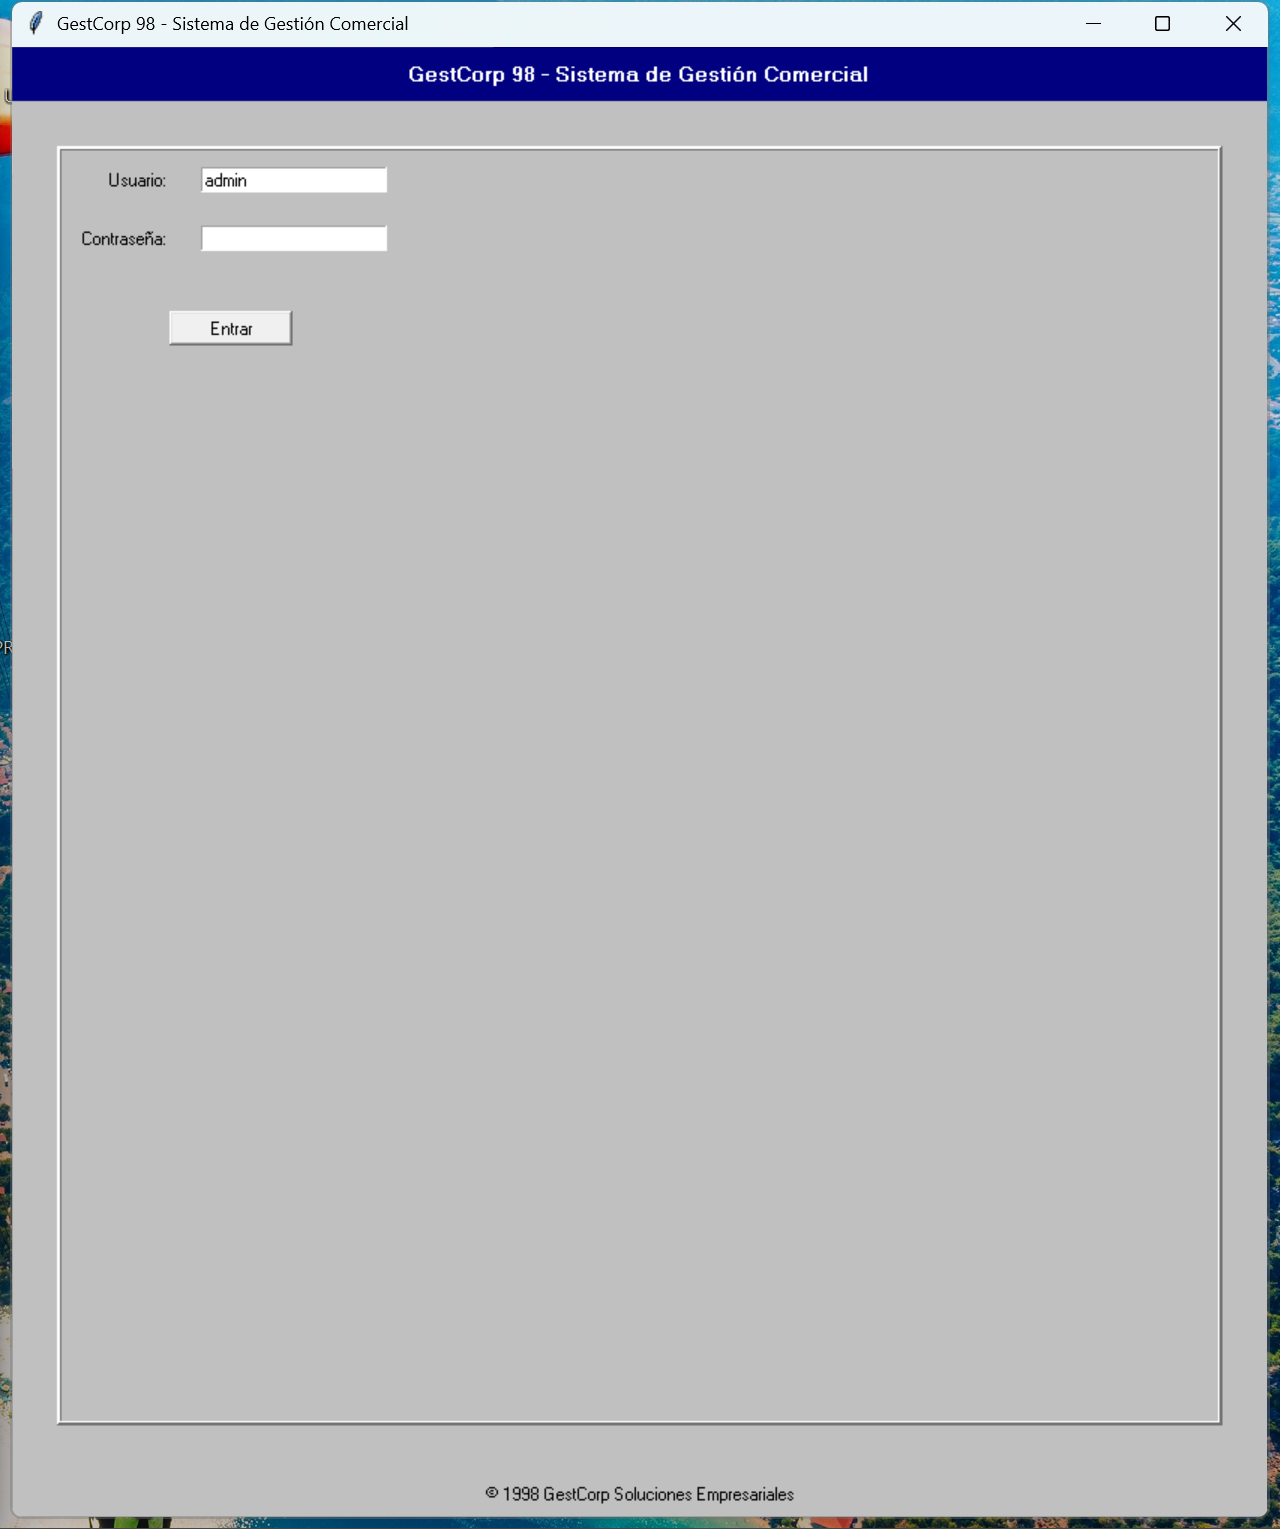

In [94]:
import ctypes.wintypes
import subprocess
import sys
import time

import pygetwindow as gw

TITULO_VENTANA = "GestCorp 98 - Sistema de Gestión Comercial"

proceso_gestcorp98 = subprocess.Popen([sys.executable, "-m", "gestcorp98.main"], cwd="..")

ventana = None
for _ in range(20):
    time.sleep(0.5)
    candidatas = gw.getWindowsWithTitle(TITULO_VENTANA)
    if candidatas:
        ventana = candidatas[0]
        break
if ventana is None:
    raise RuntimeError(f"no encontre la ventana '{TITULO_VENTANA}' tras 10s")

# zona util de la pantalla, sin la barra de tareas (SPI_GETWORKAREA)
area = ctypes.wintypes.RECT()
ctypes.windll.user32.SystemParametersInfoW(0x0030, 0, ctypes.byref(area), 0)
mitad = (area.right - area.left) // 2

# la app arranca maximizada ("zoomed"): hay que restaurarla antes de poder moverla
ventana.restore()
time.sleep(0.5)
ventana.moveTo(area.left + mitad, area.top)
ventana.resizeTo(mitad, area.bottom - area.top)
time.sleep(0.5)

# copia en numeros fijos de donde quedo la ventana: `ventana` lee su posicion
# en vivo de Windows y deja de valer en cuanto la app se cierra, pero la celda
# que extrae el flujo RPA necesita la posicion que tenia durante la grabacion
rect_ventana = {"left": ventana.left, "top": ventana.top, "ancho": ventana.width, "alto": ventana.height}

vision_tools.fijar_region_captura(ventana.left, ventana.top, ventana.width, ventana.height)
print(f"GestCorp 98 en ({ventana.left}, {ventana.top}), tamano {ventana.width}x{ventana.height}")
vision_tools.capturar_pantalla()  # lo que vera el agente a partir de ahora

## Ejecutar el agente

Te pide la instruccion (p.ej. pega la de `prompts/login_alta_cliente.txt`), le da el foco a la app y lanza el agente. Usamos `agent.stream` en vez de `agent.invoke` para que cada mensaje (cada tool que decide llamar y lo que devuelve) se imprima **en cuanto ocurre**, no todo de golpe al final: asi lo vas viendo a la izquierda mientras la app se mueve a la derecha.

Si el agente para antes de tiempo (mensaje vacio, o Groq rechaza su respuesta) sin haber escrito su RESUMEN FINAL, se le pide que continue con todo el historial.

Puedes volver a ejecutar esta celda tantas veces como quieras sin cerrar la app.

In [95]:
instruccion = input("Instruccion para el agente: ")

try:
    ventana.activate()
except Exception as exc:
    # pygetwindow a veces lanza aqui aunque el cambio de foco SI funcione
    # (restriccion de Windows sobre que proceso puede robar el foco); en
    # cualquier caso la primera accion del agente es un clic sobre la app
    print(f"aviso: activate() lanzo un error ({exc}), sigo de todas formas")
time.sleep(0.5)

from groq import BadRequestError

# Si el agente para sin terminar (mensaje vacio, o Groq rechaza su respuesta)
# y no ha escrito su RESUMEN FINAL, le decimos que continue con todo el historial.
MAX_REANUDACIONES = 5
mensajes = [("user", instruccion)]
for intento in range(MAX_REANUDACIONES + 1):
    try:
        for estado in agent.stream({"messages": mensajes}, stream_mode="values"):
            estado["messages"][-1].pretty_print()
        fallo_groq = False
    except BadRequestError as exc:
        # el modelo genero algo que Groq no puede leer (una llamada a tool con
        # JSON roto o una respuesta vacia). Esa respuesta no entra en el
        # historial, asi que se trata igual que una parada a medias
        print(f">> Groq rechazo la respuesta del modelo ({exc.body['error']['code']})")
        fallo_groq = True
    mensajes = estado["messages"]
    if not fallo_groq and "RESUMEN FINAL" in str(mensajes[-1].content):
        break
    if intento == MAX_REANUDACIONES:
        print(">> el agente sigue parando sin terminar; me rindo")
        break
    print(">> paro sin terminar; le pido que continue")
    mensajes = mensajes + [
        ("user", "No has terminado. Continua con el siguiente paso pendiente del proceso.")
    ]

time.sleep(1)  # dar tiempo a que la UI reaccione a la ultima accion
vision_tools.capturar_pantalla()

================================ Human Message =================================

OBJETIVO: dar de alta en GestCorp 98 un cliente nuevo llamado "David" y crearle un pedido. PASO 1, INICIAR SESIÓN: estás en la ventana de login. Escribe "admin" en el campo "Contraseña" y pulsa el botón "Entrar". PASO 2, DAR DE ALTA EL CLIENTE: Abajo está el formulario "Alta de cliente", con los campos en blanco Nombre, NIF, Email, Teléfono y Ciudad. Escribe "David" en el campo en blanco correspondiente a Nombre, "12345" en el campo en blanco correspondiente a NIF y "Albacete es top" en el campo en blanco correspondiente a Ciudad (Email y Teléfono se quedan vacíos). Pulsa "Añadir cliente".PASO 3, CREAR EL PEDIDO: pulsa la pestaña "Pedidos" (arriba, junto a "Clientes"). El formulario "Nuevo pedido" está en la parte de abajo de la ventana con la etiqueta "Cliente:" con un desplegable a su derecha, la etiqueta "Producto:" con otro desplegable a su derecha, y la etiqueta "Cantidad:" con un campo de texto pequ

Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


================================= Tool Message =================================
Name: rellenar_campo

{"resultado": "escrito 'admin' en: campo Contraseña en la ventana de login", "acciones": [{"accion": "escribir", "elemento": "campo Contraseña en la ventana de login", "x": 1521, "y": 240, "texto": "admin"}]}
================================== Ai Message ==================================
Tool Calls:
  pulsar (fc_cd95ce46-dc5f-4ee4-ae23-3a048d528946)
 Call ID: fc_cd95ce46-dc5f-4ee4-ae23-3a048d528946
  Args:
    descripcion: botón Entrar en la ventana de login


Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


================================= Tool Message =================================
Name: pulsar

{"resultado": "pulsado: botón Entrar en la ventana de login", "acciones": [{"accion": "click", "elemento": "botón Entrar en la ventana de login", "x": 1510, "y": 327}]}


Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


... (6 outputs left out)

================================= Tool Message =================================
Name: verificar_alta_cliente

SI: todos los campos están bien.
- Nombre: BIEN (hay escrito 'David')
- NIF: BIEN (hay escrito '12345')
- Ciudad: BIEN (hay escrito 'Albacete es top')


Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


================================== Ai Message ==================================
Tool Calls:
  pulsar (fc_6327604e-7479-4dfc-839f-5f757f6ab048)
 Call ID: fc_6327604e-7479-4dfc-839f-5f757f6ab048
  Args:
    descripcion: botón Añadir cliente en el formulario Alta de cliente
================================= Tool Message =================================
Name: pulsar

{"resultado": "pulsado: botón Añadir cliente en el formulario Alta de cliente", "acciones": [{"accion": "click", "elemento": "botón Añadir cliente en el formulario Alta de cliente", "x": 1766, "y": 1457}]}


RateLimitError: Error code: 429 - {'error': {'message': 'Rate limit reached for model `openai/gpt-oss-120b` in organization `org_01knkp1pgqe08shh5k8xbdwk59` service tier `on_demand` on tokens per day (TPD): Limit 200000, Used 199039, Requested 2489. Please try again in 11m0.096s. Need more tokens? Upgrade to Dev Tier today at https://console.groq.com/settings/billing', 'type': 'tokens', 'code': 'rate_limit_exceeded'}}

## Del agente al RPA determinista: extraer los pasos buenos

`mensajes` (de la celda del agente) es la **grabacion** de toda la ejecucion: cada tool que llamo el agente, con sus argumentos y lo que le devolvio. De ahi sacamos un flujo de clics fijo, sin agente ni vision:

- `pulsar`, `rellenar_campo` y `seleccionar_en_desplegable` devuelven en su resultado las **acciones fisicas** que hicieron (clic o escritura, con coordenadas y que elemento era): esas son los pasos del flujo. Un desplegable son dos clics (abrir la lista y la opcion).
- `verificar_alta_cliente` y `verificar_pedido` -> fuera: el RPA no tiene vision.

Limpieza de redundancias:
- Cada escritura se reproduce como **borrar + escribir** (algunos campos vienen rellenos, p.ej. Cantidad trae un "1"), asi que los `borrar_campo` del agente sobran.
- Si un mismo campo (mismas coordenadas o misma descripcion) se escribio varias veces seguidas (una correccion tras verificar, aunque la primera cayera en otro sitio), solo vale **la ultima**.
- Dos clics identicos seguidos cuentan como uno.

Las coordenadas se guardan **relativas a la ventana** (no a la pantalla), y cada grabacion se guarda en su propio fichero `flujos/flujo_AAAAMMDD_HHMMSS.json` (fecha y hora), junto con el prompt que se le dio al agente: queda registro de todas y ninguna sobrescribe a otra.

In [ ]:
import json
from datetime import datetime
from pathlib import Path

from langchain_core.messages import AIMessage, ToolMessage

# posicion de la ventana durante la grabacion, guardada en la celda de abrir GestCorp
# (no usamos `ventana`: si la app ya se cerro, Windows da error 1400)
origen_x, origen_y = rect_ventana["left"], rect_ventana["top"]

# 1) recorrer la grabacion: cada tool devuelve en su resultado las acciones
#    fisicas que hizo, con coordenadas de pantalla
resultados = {m.tool_call_id: m.content for m in mensajes if isinstance(m, ToolMessage)}
TOOLS_DE_ACCION = ("pulsar", "rellenar_campo", "borrar_campo", "seleccionar_en_desplegable")

# 2) pasarlas a coordenadas relativas a la ventana. Los "borrar" no hacen
#    falta: al reproducir, cada escritura vacia el campo antes de escribir
pasos = []
for m in mensajes:
    if not isinstance(m, AIMessage):
        continue
    for tc in m.tool_calls or []:
        if tc["name"] not in TOOLS_DE_ACCION or tc["id"] not in resultados:
            continue  # las verificaciones no pasan al flujo
        try:
            acciones = json.loads(resultados[tc["id"]])["acciones"]
        except (ValueError, KeyError):
            continue  # la tool fallo (error, no JSON)
        for acc in acciones:
            if acc["accion"] == "borrar":
                continue
            paso = {"accion": acc["accion"], "elemento": acc["elemento"],
                    "x": acc["x"] - origen_x, "y": acc["y"] - origen_y}
            if acc["accion"] == "escribir":
                paso["texto"] = acc["texto"]
            pasos.append(paso)

# 3) quitar redundancias
limpios = []
for paso in pasos:
    previo = limpios[-1] if limpios else None
    if paso["accion"] == "click" and previo == paso:
        continue  # dos clics identicos seguidos
    if paso["accion"] == "escribir":
        # mismo campo (mismas coordenadas o misma descripcion, p.ej. "campo
        # Ciudad") ya escrito desde el ultimo clic -> solo vale la ultima
        # escritura. Asi se descartan tambien las que cayeron en un sitio
        # equivocado y la verificacion obligo a repetir en el bueno.
        for i in range(len(limpios) - 1, -1, -1):
            if limpios[i]["accion"] == "click":
                break
            mismas_coords = (limpios[i]["x"], limpios[i]["y"]) == (paso["x"], paso["y"])
            mismo_campo = paso["elemento"] != "?" and limpios[i]["elemento"] == paso["elemento"]
            if mismas_coords or mismo_campo:
                del limpios[i]
                break
    limpios.append(paso)

fecha = datetime.now()
flujo = {
    "fecha": fecha.isoformat(timespec="seconds"),
    "instruccion": instruccion,  # el prompt que se le dio al agente, para saber que flujo es
    "ventana": {"ancho": rect_ventana["ancho"], "alto": rect_ventana["alto"]},
    "pasos": limpios,
}
# un fichero por grabacion (con fecha y hora en el nombre): nunca se sobrescribe ninguno
ruta_flujo = Path(f"flujos/flujo_{fecha:%Y%m%d_%H%M%S}.json")
ruta_flujo.parent.mkdir(exist_ok=True)
ruta_flujo.write_text(json.dumps(flujo, ensure_ascii=False, indent=2), encoding="utf-8")

print(f"{len(pasos)} acciones grabadas -> {len(limpios)} pasos tras limpiar (guardado en {ruta_flujo})\n")
for n, p in enumerate(limpios, 1):
    texto = f" <- '{p['texto']}'" if "texto" in p else ""
    print(f"{n:2}. {p['accion']:8} {p['elemento']}{texto}  ({p['x']}, {p['y']})")


## Reproducir el flujo con RPA puro (sin agente, sin vision)

Cierra la GestCorp 98 que este abierta (sin tocar la base de datos), la abre de nuevo en la mitad derecha con el mismo tamano que en la grabacion y ejecuta con `pyautogui` los pasos del flujo que acaba de generar la celda anterior (`ruta_flujo`).

No usa el agente ni UI-TARS: solo `pyautogui` con las coordenadas grabadas, por eso va mucho mas rapido.

In [ ]:
import ctypes
import ctypes.wintypes
import json
import subprocess
import sys
import time
from pathlib import Path

import pyautogui
import pygetwindow as gw
import pyperclip

TITULO_VENTANA = "GestCorp 98 - Sistema de Gestión Comercial"
PAUSA_CLICK = 1.0     # tras un clic la UI cambia (login, pestana, lista que se abre)
PAUSA_ESCRIBIR = 0.3

# el flujo que acaba de generar la celda anterior
print(f"reproduciendo {ruta_flujo}")
flujo = json.loads(ruta_flujo.read_text(encoding="utf-8"))

# 1) cerrar la GestCorp que uso el agente, para empezar el RPA desde el login
proceso_gestcorp98.terminate()
proceso_gestcorp98.wait(timeout=5)

# 2) abrir GestCorp 98 en la mitad derecha, con el tamano de la grabacion
proceso_gestcorp98 = subprocess.Popen([sys.executable, "-m", "gestcorp98.main"], cwd="..")
ventana = None
for _ in range(20):
    time.sleep(0.5)
    candidatas = gw.getWindowsWithTitle(TITULO_VENTANA)
    if candidatas:
        ventana = candidatas[0]
        break
if ventana is None:
    raise RuntimeError(f"no encontre la ventana '{TITULO_VENTANA}' tras 10s")

area = ctypes.wintypes.RECT()
ctypes.windll.user32.SystemParametersInfoW(0x0030, 0, ctypes.byref(area), 0)
mitad = (area.right - area.left) // 2
ventana.restore()
time.sleep(0.5)
ventana.moveTo(area.left + mitad, area.top)
ventana.resizeTo(flujo["ventana"]["ancho"], flujo["ventana"]["alto"])
time.sleep(0.5)
try:
    ventana.activate()
except Exception:
    pass  # mismo aviso falso de Windows que en la celda del agente
time.sleep(0.5)

# 3) ejecutar los pasos (coordenadas relativas a la ventana -> absolutas)
for n, paso in enumerate(flujo["pasos"], 1):
    x, y = ventana.left + paso["x"], ventana.top + paso["y"]
    if paso["accion"] == "click":
        print(f"{n:2}. click     {paso['elemento']}")
        pyautogui.click(x, y)
        time.sleep(PAUSA_CLICK)
    else:
        print(f"{n:2}. escribir  {paso['elemento']} <- '{paso['texto']}'")
        # igual que las tools borrar_campo + escribir_texto
        pyautogui.click(x, y)
        pyautogui.press("end")
        pyautogui.press("backspace", presses=50)
        pyperclip.copy(paso["texto"])
        pyautogui.hotkey("ctrl", "v")
        time.sleep(PAUSA_ESCRIBIR)

print("\nflujo terminado")


## Limpieza

Cierra el proceso de GestCorp 98 cuando termines de probar.

In [ ]:
proceso_gestcorp98.terminate()

## Anexo: ¿puede UI-TARS responder preguntas, no solo localizar?

**Ya sabemos que sí**: de aquí salieron las tools de verificación. Se deja como referencia. Necesita GestCorp 98 abierta (ejecuta antes la celda de abrirla); si dejas la pregunta vacía, la celda no hace nada.

Prueba suelta, todavia sin conectarla a las tools ni al agente. Ejecutala con GestCorp 98 **todavia abierto**, tantas veces como quieras. Te pide dos cosas:

1. **La pregunta**, la que tu quieras (p.ej. "Que texto hay escrito en este campo? Responde solo con el texto" o "Aparece un cliente llamado Lucas en el listado? Responde si o no").
2. **El elemento en el que fijarse** (opcional): si escribes algo (p.ej. "el campo de texto Nombre del formulario Alta de cliente"), primero se localiza con UI-TARS y la pregunta se hace solo sobre un recorte alrededor de ese elemento. Si lo dejas vacio, la pregunta se hace sobre toda la ventana de la app.

Si responde bien a preguntas de verificacion, lo convertimos en una tool de verdad; si no, probamos otra cosa (p.ej. un segundo modelo tipo qwen2.5vl).

In [ ]:
pregunta = input("Pregunta para UI-TARS (vacio = saltar el anexo): ").strip()
zona = input("Elemento en el que fijarse (deja vacio para mirar toda la ventana): ").strip() if pregunta else ""

if not pregunta:
    print("anexo omitido")
elif zona:
    coords = vision_tools.localizar_elemento_en_pantalla(zona)
    print(f"'{zona}' localizado en: ({coords['x']}, {coords['y']})")
    respuesta = vision_tools.preguntar_sobre_pantalla(pregunta, x=coords["x"], y=coords["y"])
else:
    respuesta = vision_tools.preguntar_sobre_pantalla(pregunta)

if pregunta:
    print(f"respuesta de UI-TARS: {respuesta!r}")